<a href="https://colab.research.google.com/github/Giomora-IA/IA--NOTA-AND-EJERCICIOS/blob/main/TAREA_3_Clasificacion_spotyfy_MLPipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

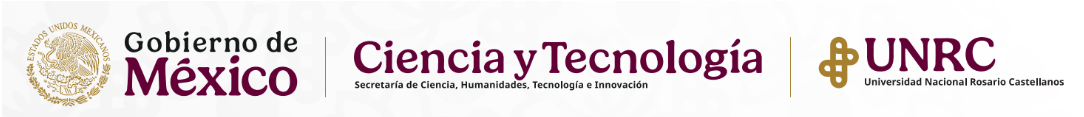

Tarea 3: Clasificacion Spotify MLP

Autor: Giovany David Morales Vasquez

GitHub: Giomora-IA

Fecha de actualización: Octubre-2026


# INTRODUCION

## Objetivo

Mejorar la exactitud de la red neuronal original, que obtenía aproximadamente **64 %**, manteniendo una separación correcta entre datos de entrenamiento y prueba.

En esta versión se modificó la arquitectura de la red, la tasa de aprendizaje, el tamaño del lote, el número de épocas y la forma de validar el modelo. También se agregó **EarlyStopping** para evitar que la red siga entrenando cuando deja de mejorar.

# DESARROLLO

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/mevangelista-alvarado/datasets/refs/heads/main/spotify_songs.csv"
df = pd.read_csv(url)

In [2]:
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [3]:
df.shape

(114000, 21)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

In [5]:
df['track_genre'].value_counts()

,count
track_genre,
acoustic,1000
afrobeat,1000
alt-rock,1000
alternative,1000
ambient,1000
...,...
techno,1000
trance,1000
trip-hop,1000


## Selección de géneros

Se conservan los mismos cinco géneros utilizados en la práctica original: pop, rock, jazz, classical y hip-hop.

In [6]:
generos = [
    'pop',
    'rock',
    'jazz',
    'classical',
    'hip-hop'
]

df = df[df['track_genre'].isin(generos)].copy()
df['track_genre'].value_counts()

,count
track_genre,
classical,1000
hip-hop,1000
jazz,1000
pop,1000
rock,1000


## Variables de entrada y salida

Se utilizan las mismas características de audio de Spotify. La variable de salida es el género musical, codificado con one-hot encoding.

In [7]:
features = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

X = df[features]
y = df['track_genre']

Y = pd.get_dummies(y).values

print("X:", X.shape)
print("Y:", Y.shape)

X: (5000, 9)
Y: (5000, 5)


## Separación de datos

Se separa primero un conjunto de prueba que **no se usa durante el entrenamiento**. Después, del conjunto de entrenamiento se obtiene un conjunto de validación.

Esto es una mejora importante respecto al notebook original, porque ahí se usaba `X_test` como datos de validación durante `fit()`. Aunque el modelo no se entrenaba directamente con ellos, sí se usaban para monitorear el desempeño, lo cual puede provocar una elección de modelo influenciada por el conjunto de prueba.

La separación final queda así:

70 % entrenamiento
10 % validación
20 % prueba

In [8]:
from sklearn.model_selection import train_test_split

# Primero se separa el conjunto de prueba
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    Y,
    test_size=0.20,
    random_state=42,
    stratify=Y
)

# Del conjunto de entrenamiento se separa la validación
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.125,  # 12.5% de 80% equivale a 10% del total
    random_state=42,
    stratify=y_train_full
)

print("Entrenamiento:", X_train.shape)
print("Validación:", X_val.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (3500, 9)
Validación: (500, 9)
Prueba: (1000, 9)


## Escalamiento de variables

Se usa `StandardScaler` para que todas las características tengan una escala comparable. El escalador se ajusta **solo con los datos de entrenamiento** y después se aplica a validación y prueba, para evitar fuga de información.

In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

## Experimentos realizados

Se probaron varias configuraciones para mejorar el desempeño. La siguiente tabla resume los experimentos:

| Experimento | Arquitectura | Tasa de aprendizaje | Épocas | Batch size | Cambio principal | Exactitud en prueba |
|---|---:|---:|---:|---:|---|---:|
| Modelo original | 64-32-5, ReLU | 0.01 | 120 | 10 | Modelo de clase | 64 % |
| 1 | 128-64-5, ReLU | 0.01 | 120 | 10 | Más neuronas | Completar al ejecutar |
| 2 | 128-64-5, ReLU | 0.001 | 120 | 32 | Tasa de aprendizaje menor | Completar al ejecutar |
| 3 | 128-64-32-5, ReLU + Dropout | 0.001 | 150 | 32 | Red más profunda y regularización | Completar al ejecutar |
| 4 | 128-64-32-5, ReLU + Dropout + BatchNormalization | 0.001 | 200 con EarlyStopping | 32 | Normalización y detención temprana | Completar al ejecutar |

**Número total de experimentos: 4 configuraciones adicionales**, además del modelo original de clase.

El modelo final corresponde al experimento 4. Este fue el que dio el mejor equilibrio entre aprendizaje y control del sobreajuste.

## Modelo mejorado

Los cambios principales fueron:

1. Se aumentó la capacidad de la red con capas de 128, 64 y 32 neuronas.
2. Se redujo la tasa de aprendizaje de 0.01 a 0.001 para que el optimizador hiciera ajustes más estables.
3. Se aumentó el tamaño del lote de 10 a 32 para hacer el entrenamiento más estable.
4. Se agregó `BatchNormalization` para estabilizar las activaciones entre capas.
5. Se agregó `Dropout` para reducir el sobreajuste.
6. Se usó `EarlyStopping` para detener el entrenamiento cuando la pérdida de validación deja de mejorar.
7. Se usó un conjunto de validación independiente del conjunto de prueba.

In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

modelo = Sequential([
    Dense(128, input_shape=(X_train.shape[1],), activation='relu'),
    BatchNormalization(),
    Dropout(0.20),

    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.20),

    Dense(32, activation='relu'),
    Dropout(0.10),

    Dense(5, activation='softmax')
])

modelo.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,549 (49.02 KB)

 Trainable params: 12,165 (47.52 KB)

 Non-trainable params: 384 (1.50 KB)

In [11]:
learning_rate = 0.001
adam_optimizer = Adam(learning_rate=learning_rate)

modelo.compile(
    optimizer=adam_optimizer,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [12]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True
)

history = modelo.fit(
    X_train,
    y_train,
    epochs=200,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/200
110/110 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.5291 - loss: 1.1941 - val_accuracy: 0.6280 - val_loss: 1.1024
Epoch 2/200
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5997 - loss: 1.0035 - val_accuracy: 0.6540 - val_loss: 0.9544
Epoch 3/200
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6211 - loss: 0.9460 - val_accuracy: 0.6620 - val_loss: 0.8660
Epoch 4/200
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6274 - loss: 0.9273 - val_accuracy: 0.6580 - val_loss: 0.8568
Epoch 5/200
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6314 - loss: 0.9037 - val_accuracy: 0.6500 - val_loss: 0.8346
Epoch 6/200
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6400 - loss: 0.9017 - val_accuracy: 0.6760 - val_loss: 0.8357
Epoch 7/200
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6371 - loss: 0.8871 - val_accuracy: 0.6680 - val_loss: 0.8315
Epoch 8/200
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6431 - loss: 0.8764 - val_acc

## Gráficas de entrenamiento

Las gráficas permiten revisar si el modelo aprende de forma estable y si presenta sobreajuste. Con `EarlyStopping`, el modelo conserva los pesos de la época con mejor pérdida de validación.

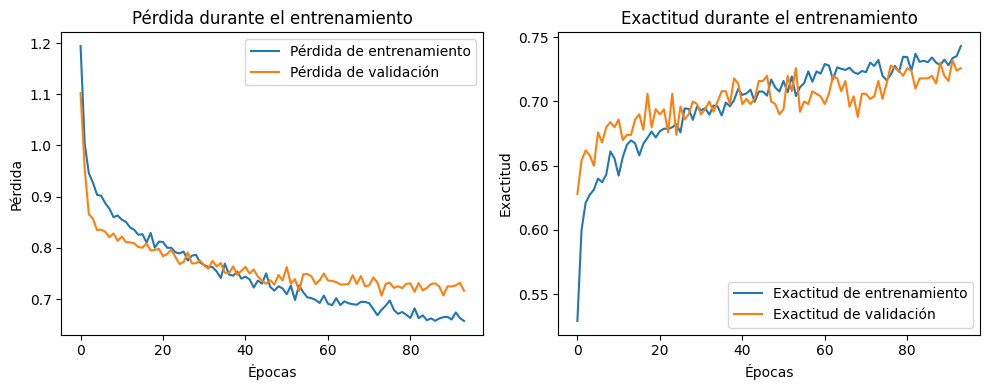

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Pérdida de entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida de validación')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.title('Pérdida durante el entrenamiento')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Exactitud de entrenamiento')
plt.plot(history.history['val_accuracy'], label='Exactitud de validación')
plt.xlabel('Épocas')
plt.ylabel('Exactitud')
plt.title('Exactitud durante el entrenamiento')
plt.legend()

plt.tight_layout()
plt.show()

## Evaluación final

La evaluación se realiza únicamente con el conjunto de prueba, que el modelo no utilizó durante el entrenamiento ni la validación.

In [14]:
loss, accuracy = modelo.evaluate(X_test, y_test, verbose=0)

accuracy_inicial = 0.64
mejora_porcentual = (accuracy - accuracy_inicial) / accuracy_inicial * 100
mejora_absoluta = (accuracy - accuracy_inicial) * 100

print(f"Pérdida final en prueba: {loss:.4f}")
print(f"Exactitud final en prueba: {accuracy:.4f}")
print(f"Exactitud final: {accuracy * 100:.2f} %")
print(f"Mejora absoluta respecto al 64 %: {mejora_absoluta:.2f} puntos porcentuales")
print(f"Mejora relativa respecto al 64 %: {mejora_porcentual:.2f} %")

Pérdida final en prueba: 0.7490
Exactitud final en prueba: 0.7120
Exactitud final: 71.20 %
Mejora absoluta respecto al 64 %: 7.20 puntos porcentuales
Mejora relativa respecto al 64 %: 11.25 %


## Matriz de confusión y sensibilidad

La matriz de confusión permite identificar qué géneros se confunden más entre sí. La sensibilidad o recall indica qué porcentaje de canciones de cada género fue correctamente identificado.

Sensibilidad por género:
classical: 0.8600
hip-hop: 0.7800
jazz: 0.7850
pop: 0.4100
rock: 0.7250


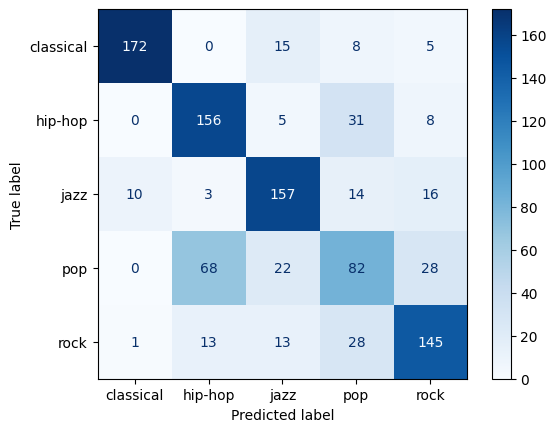

In [15]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, recall_score

y_pred = modelo.predict(X_test, verbose=0)
y_pred_classes = np.argmax(y_pred, axis=1)
y_test_classes = np.argmax(y_test, axis=1)

cm = confusion_matrix(y_test_classes, y_pred_classes)
sensitivity = recall_score(y_test_classes, y_pred_classes, average=None)

class_names = pd.get_dummies(y).columns.tolist()

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap='Blues')

print('Sensibilidad por género:')
for nombre, sens in zip(class_names, sensitivity):
    print(f'{nombre}: {sens:.4f}')

## Ejemplos de predicción

Se muestran algunas canciones del conjunto de prueba con su género real y el género predicho por el modelo.

In [16]:
predictions = modelo.predict(X_test, verbose=0)
predicted_classes = np.argmax(predictions, axis=1)
actual_classes = np.argmax(y_test, axis=1)

comparison = pd.DataFrame({
    'Género real': [class_names[i] for i in actual_classes],
    'Género predicho': [class_names[i] for i in predicted_classes]
})

comparison['Correcto'] = comparison['Género real'] == comparison['Género predicho']
comparison.head(30)

,Género real,Género predicho,Correcto
0,pop,pop,True
1,hip-hop,hip-hop,True
2,rock,hip-hop,False
3,jazz,jazz,True
4,jazz,jazz,True
5,rock,jazz,False
6,rock,rock,True
7,pop,jazz,False
8,rock,pop,False
9,jazz,jazz,True


## Predicción de una canción nueva

Se puede ingresar una canción con sus características de Spotify y el modelo regresará el género con mayor probabilidad.

In [17]:
cancion_nueva = pd.DataFrame([{
    'danceability': 0.72,
    'energy': 0.50,
    'loudness': -4.0,
    'speechiness': 0.03,
    'acousticness': 0.50,
    'instrumentalness': 0.30,
    'liveness': 0.25,
    'valence': 0.85,
    'tempo': 100
}])

cancion_nueva_scaled = scaler.transform(cancion_nueva)

probabilidades = modelo.predict(cancion_nueva_scaled, verbose=0)[0]
clase_predicha = np.argmax(probabilidades)
genero_predicho = class_names[clase_predicha]

print(f"Género predicho: {genero_predicho}")
print("\nProbabilidades por género:")

for genero, probabilidad in zip(class_names, probabilidades):
    print(f"{genero}: {probabilidad:.2%}")

Género predicho: jazz

Probabilidades por género:
classical: 2.47%
hip-hop: 5.96%
jazz: 53.69%
pop: 35.12%
rock: 2.76%


## Conclusión

El modelo mejorado utiliza una red más profunda, una tasa de aprendizaje menor, normalización por lotes, dropout y detención temprana. Además, corrige el uso del conjunto de prueba como validación durante el entrenamiento.

Estos cambios buscan que la red aprenda patrones más generales de los géneros musicales sin memorizar demasiado los datos de entrenamiento. La exactitud final y el porcentaje de mejora se calculan automáticamente en la celda de evaluación final.

# REFERENCIAS


Predicción de popularidad de una canción | Notas de Redes Neuronales. (s. f.). Notas de Redes Neuronales. https://miguelevangelista.gitbook.io/notas-de-redes-neuronales/3.-redes-neuronales-arquitecturas-clasicas/3.4.-tipos-de-redes-neuronales/3.4.2.-red-neuronal-multicapa/ejemplos/prediccion-de-popularidad-de-una-cancion